# 02 · Reproducing the reference article (RQ1)

**Goal.** Re-implement the pipeline of Rodríguez et al. (2010) on the public S1 data and compare the results.

**Pipeline.** Resistance R → conductance G = 1/R → per-sensor *static parameter* ΔG = Gmax − Gmin (the paper does not give the formula, so we also test the relative variant (Gmax − Gmin)/Gmin) → mean-centring → PCA for the 2-D plot → MLP with 10 hidden neurons trained by backpropagation with an adaptive learning rate → leave-one-out (LOO).

**Deviations.** (1) Python/scikit-learn instead of MATLAB 7.5. (2) The paper's network has *one* output neuron, which is ambiguous for several classes, so we use 3 softmax outputs. (3) Besides LOO we report 10 × repeated stratified 5-fold CV, and we repeat LOO with 3 random MLP initialisations, because a single LOO number on 58 samples is noisy.

Code: `src/experiments/s1_baseline.py`.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30); pd.set_option('display.precision', 3)
R = ROOT / 'results'; F = R / 'figures'; A = R / 'ablations'
def show(p, w=650):
    p = Path(p)
    display(Image(filename=str(p), width=w)) if p.exists() else print('missing figure:', p.name)
def table(p, **kw):
    p = Path(p)
    return pd.read_csv(p, **kw) if p.exists() else print('missing table:', p.name)

## PCA of the static parameter
`PC1+PC2` should be compared with the paper's 99.62 % (analysis 1) and > 99 % (analysis 2).

In [2]:
table(R / 'baseline_pca.csv')

,feature,scaling,PC1,PC2,PC1+PC2
0,dG-abs,center,0.985,0.010,0.996
1,dG-abs,std,0.787,0.149,0.936
2,dG-rel,center,0.979,0.013,0.992
3,dG-rel,std,0.763,0.154,0.917


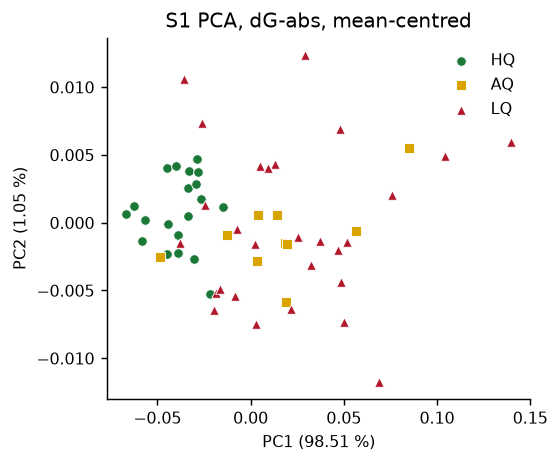

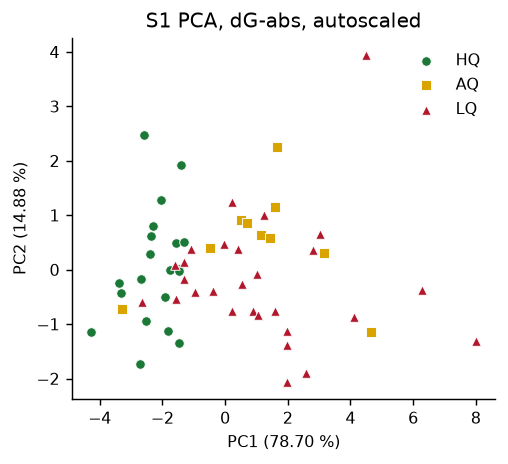

In [3]:
show(F / 'baseline_pca_dG-abs_center.png', 420); show(F / 'baseline_pca_dG-abs_std.png', 420)

**Why mean-centring gives such high explained variance.** Without scaling, PCA is dominated by the sensors whose ΔG has the largest spread (here SP-AQ3), so two components capture almost all the variance. After autoscaling (each sensor to unit variance) the figure drops, because every sensor then counts equally. Explained variance measures compression, not class separation.

## MLP accuracy: LOO vs repeated 5-fold
Variant names: `feature | input scaling | solver`. `none` = raw ΔG, `center` = mean-centring only (as in the paper), `std` = autoscaling.

In [4]:
b = table(R / 'baseline.csv')
b[['variant','scheme','n_repeats','accuracy_mean','accuracy_std','balanced_accuracy_mean','macro_f1_mean']]

,variant,scheme,n_repeats,accuracy_mean,accuracy_std,balanced_accuracy_mean,macro_f1_mean
0,dG-abs|none|sgd,loo,3,0.511,0.065,0.372,0.311
1,dG-abs|none|adam,loo,3,0.690,0.017,0.559,0.508
2,dG-abs|center|sgd,loo,3,0.517,0.075,0.381,0.331
3,dG-abs|center|adam,loo,3,0.718,0.036,0.594,0.548
4,dG-abs|std|sgd,loo,3,0.707,0.034,0.653,0.653
5,dG-abs|std|adam,loo,3,0.753,0.020,0.690,0.692
6,dG-rel|none|sgd,loo,3,0.724,0.030,0.594,0.558
7,dG-rel|none|adam,loo,3,0.718,0.055,0.679,0.683
8,dG-rel|center|sgd,loo,3,0.833,0.010,0.775,0.776
9,dG-rel|center|adam,loo,3,0.793,0.017,0.733,0.731


**How to read it.** The absolute ΔG values are tiny (about 0.001–0.2 mS). With plain SGD and no autoscaling, the network barely moves away from predicting the majority class (LQ, 48 %): about 52–55 % accuracy. Adam or autoscaling lift the absolute feature to 69–75 %, and the relative feature ΔG/Gmin, which is scale-free, reaches 79–83 %. Compare `loo` with `rskf5` for each variant: the gap shows how optimistic LOO is on this data (ablation AB7).

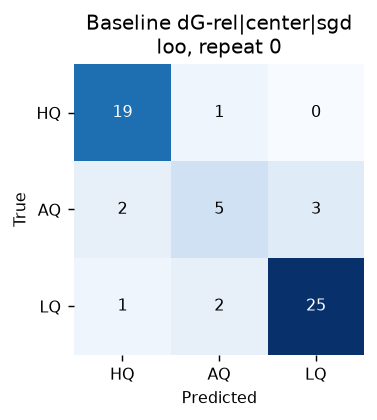

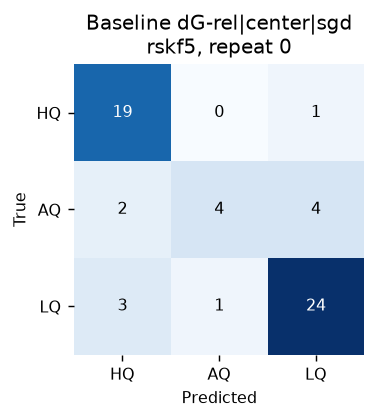

In [5]:
show(F / 'baseline_confusion_loo.png', 330); show(F / 'baseline_confusion_rskf5.png', 330)